# Planning Agent Architecture

This notebook implements a complete **Plan-and-Execute** multi-agent pattern:
1. **Planner Agent**: Analyzes the user request, formulates an overall goal, and plans a sequence of actionable tasks with explicit dependencies.
2. **Executor Agent**: Reads the planned tasks from state, executes them step-by-step with dependency checking, updates task status (`completed`, `failed`, `aborted`), and records errors.
3. **Summarization Agent**: Gathers the individual results from all executed tasks and synthesizes them into a single, cohesive, unified final response.

## 1. Imports and Configuration

In [60]:
import os
from pathlib import Path
from dotenv import load_dotenv

from typing import Literal, Annotated
from pydantic import BaseModel, Field

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, BaseMessage, AIMessage
from langgraph.graph import StateGraph, START, END, add_messages

In [61]:
# Locate and load the .env file from the project directory
env_path = None
for parent_directory in [Path.cwd()] + list(Path.cwd().parents):
    candidate_path = parent_directory / ".env"
    if candidate_path.is_file():
        env_path = candidate_path
        break

if env_path:
    load_dotenv(env_path)

openai_api_key = os.getenv("OPENAI_API_KEY")

# LangSmith project tracing configuration
os.environ["LANGSMITH_PROJECT"] = "planning-agent"
os.environ["LANGCHAIN_PROJECT"] = "planning-agent"
os.environ["LANGCHAIN_TRACING_V2"] = "true"

## 2. LLM Initialization

In [62]:
# Primary language model instance
model = ChatOpenAI(
    model="gpt-4.1-mini",
    api_key=openai_api_key,
    temperature=0
)

## 3. State and Data Models

- `TaskState`: Tracks an individual task, its execution status (`pending`, `in progress`, `completed`, `failed`, `aborted`), its result, and any error message.
- `State`: Shared graph state holding the message history, user query, goal, list of tasks, and the final response.

In [63]:
class TaskState(BaseModel):
    task_id: int = Field(
        description="Unique integer identifier for the task"
    )
    task: str = Field(
        description="Description of what the task involves"
    )
    task_status: Literal["pending", "in progress", "aborted", "completed", "failed"] = Field(
        default="pending",
        description="Current execution status of the task"
    )
    dependencies: list[int] = Field(
        default_factory=list,
        description="List of task IDs that must complete before this task can start"
    )
    result: str | None = Field(
        default=None,
        description="Output or result of the task upon successful completion"
    )
    error: str | None = Field(
        default=None,
        description="Error message if the task fails or is aborted"
    )


class State(BaseModel):
    messages: Annotated[list[BaseMessage], add_messages] = Field(
        default_factory=list,
        description="History of conversation messages"
    )
    user_query: str = Field(
        default="",
        description="The original question or request submitted by the user"
    )
    goal: str = Field(
        default="",
        description="The overarching objective identified by the planner"
    )
    tasks: list[TaskState] = Field(
        default_factory=list,
        description="List of individual tasks planned to achieve the goal"
    )
    current_task_id: int | None = Field(
        default=None,
        description="The ID of the task currently being executed"
    )
    final_response: str | None = Field(
        default=None,
        description="The unified final summary response produced by the summarization agent"
    )

## 4. Planner Agent

Defines the structured output schemas (`PlannedTask`, `TaskPlan`) and the `planner_agent` node that translates the user query into a sequence of tasks.

In [64]:
class PlannedTask(BaseModel):
    task_id: int = Field(
        description="Unique integer identifier for the task, starting from 1"
    )
    task: str = Field(
        description="Clear, actionable instructions for executing this step"
    )
    dependencies: list[int] = Field(
        default_factory=list,
        description="List of prerequisite task IDs that must finish before this task starts"
    )


class TaskPlan(BaseModel):
    goal: str = Field(
        description="A clear and concise summary of the overall goal to be accomplished"
    )
    tasks: list[PlannedTask] = Field(
        description="Ordered sequence of tasks required to achieve the goal"
    )


# Bind structured output schema to the model
planner_model = model.with_structured_output(TaskPlan)


def planner_agent(state: State):
    """
    Analyzes the user's query, determines the overall goal,
    and generates an ordered list of tasks with dependencies.
    """
    user_query = state.user_query
    if not user_query and state.messages:
        user_query = state.messages[-1].content

    system_prompt = (
        "You are a strategic planning agent. Analyze the user's request, identify the "
        "overall goal, and break it down into a clear, sequential list of actionable tasks. "
        "Specify any necessary prerequisite task dependencies."
    )
    system_message = SystemMessage(content=system_prompt)
    human_message = HumanMessage(content=user_query)

    prompt_messages = [system_message, human_message]
    plan_output = planner_model.invoke(prompt_messages)

    # Convert each planned task into a TaskState object for our state
    task_list = []
    for planned_task in plan_output.tasks:
        task_state = TaskState(
            task_id=planned_task.task_id,
            task=planned_task.task,
            dependencies=planned_task.dependencies,
            task_status="pending"
        )
        task_list.append(task_state)

    return {
        "goal": plan_output.goal,
        "user_query": user_query,
        "tasks": task_list,
        "messages": [
            human_message,
            AIMessage(content=f"Generated plan with {len(task_list)} tasks for goal: {plan_output.goal}")
        ]
    }

## 5. Executor Agent

Iterates through the tasks in `state.tasks`:
1. Checks prerequisite dependencies (aborts the task if any dependency failed).
2. Updates `task_status = 'in progress'`.
3. Executes the task with context from earlier completed tasks.
4. On success: sets `task_status = 'completed'` and stores `result`.
5. On failure: catches the exception, sets `task_status = 'failed'`, and stores `error`.

In [65]:
def executor_agent(state: State):
    """
    Executes each planned task in order, tracks status ('in progress', 'completed', 'failed', 'aborted'),
    and records any errors directly in the task state.
    """
    system_prompt = (
        "You are a specialized execution agent. Your job is to perform the assigned task "
        "accurately and thoroughly, taking into account any context from previously completed tasks. "
        "Do not include generic usage instructions or 'how to use this script' sections."
    )
    system_message = SystemMessage(content=system_prompt)

    # Make a copy of the tasks list so we can update each task
    task_list = [task.model_copy() for task in state.tasks]

    for current_task in task_list:
        # Check if all prerequisite dependency tasks completed successfully
        has_failed_dependency = False
        failed_dependency_ids = []

        for dependency_id in current_task.dependencies:
            for other_task in task_list:
                if other_task.task_id == dependency_id:
                    if other_task.task_status != "completed":
                        has_failed_dependency = True
                        failed_dependency_ids.append(dependency_id)

        # If any prerequisite failed, abort this task and record the reason
        if has_failed_dependency:
            current_task.task_status = "aborted"
            current_task.error = f"Prerequisite task(s) {failed_dependency_ids} did not complete successfully."
            continue

        # Mark the task as in progress
        current_task.task_status = "in progress"

        # Build context from previously completed tasks
        completed_context_items = []
        for completed_task in task_list:
            if completed_task.task_status == "completed" and completed_task.result:
                completed_context_items.append(
                    f"- Task {completed_task.task_id} ({completed_task.task}): {completed_task.result}"
                )

        if completed_context_items:
            context_text = "\n".join(completed_context_items)
        else:
            context_text = "No previous tasks completed yet."

        task_prompt = (
            f"Overall Goal: {state.goal}\n\n"
            f"Previously Completed Tasks Context:\n{context_text}\n\n"
            f"Current Task to Execute:\nTask {current_task.task_id}: {current_task.task}"
        )

        try:
            prompt_messages = [
                system_message,
                HumanMessage(content=task_prompt)
            ]
            response = model.invoke(prompt_messages)

            # Record successful completion
            current_task.result = response.content
            current_task.task_status = "completed"
            current_task.error = None

        except Exception as error_instance:
            # Record failure and capture the error message
            current_task.task_status = "failed"
            current_task.error = str(error_instance)
            current_task.result = None

    return {
        "tasks": task_list,
        "current_task_id": None
    }

## 6. Summarization Agent

Reads all task outcomes from `state.tasks`, reviews individual results and any errors, and generates a cohesive, unified final response addressing the user's overall goal.

In [66]:
def summarization_agent(state: State):
    """
    Gathers the results from all individual tasks and synthesizes them into
    a single, cohesive, unified final response without boilerplate usage instructions.
    """
    system_prompt = (
        "You are a summarization agent. Your job is to review the results of all individual "
        "tasks that were executed, and synthesize them into a clean, complete, unified final "
        "response that directly accomplishes the user's request.\n"
        "Important instruction: Do NOT include any 'How to use this script', usage instructions, "
        "or file saving/execution guide sections in the final output. Provide only the direct solution, "
        "code, and necessary technical explanations."
    )
    system_message = SystemMessage(content=system_prompt)

    # Format the status and output of each task
    formatted_task_results = []
    for task in state.tasks:
        if task.task_status == "completed":
            formatted_task_results.append(
                f"Task {task.task_id}: {task.task}\nStatus: Completed\nResult:\n{task.result}"
            )
        elif task.task_status == "failed":
            formatted_task_results.append(
                f"Task {task.task_id}: {task.task}\nStatus: Failed\nError:\n{task.error}"
            )
        elif task.task_status == "aborted":
            formatted_task_results.append(
                f"Task {task.task_id}: {task.task}\nStatus: Aborted\nReason:\n{task.error}"
            )
        else:
            formatted_task_results.append(
                f"Task {task.task_id}: {task.task}\nStatus: Pending"
            )

    all_tasks_text = "\n\n---\n\n".join(formatted_task_results)

    user_prompt = (
        f"Original User Request: {state.user_query}\n"
        f"Goal: {state.goal}\n\n"
        f"Individual Task Execution Results:\n{all_tasks_text}\n\n"
        "Please provide a comprehensive, well-structured final response integrating all the results above. "
        "Do NOT include any 'How to use this script' or usage instructions section."
    )
    human_message = HumanMessage(content=user_prompt)

    prompt_messages = [system_message, human_message]
    summary_response = model.invoke(prompt_messages)

    final_response_text = summary_response.content

    # Remove any trailing 'How to use this script' section if generated
    usage_section_markers = [
        "### How to use this script:",
        "### How to Use this Script:",
        "### How to Use This Script:",
        "## How to use this script:",
        "## How to Use this Script:",
        "## How to Use This Script:",
        "**How to use this script:**",
        "**How to Use This Script:**",
        "How to use this script:"
    ]
    for marker in usage_section_markers:
        if marker in final_response_text:
            final_response_text = final_response_text.split(marker)[0].rstrip()

    return {
        "final_response": final_response_text,
        "messages": [AIMessage(content=final_response_text)]
    }

## 7. Graph Assembly and Compilation

Connects `START -> planner_agent -> executor_agent -> summarization_agent -> END`.

In [67]:
# Initialize the StateGraph
graph = StateGraph(State)

# Add all agent nodes
graph.add_node("planner_agent", planner_agent)
graph.add_node("executor_agent", executor_agent)
graph.add_node("summarization_agent", summarization_agent)

# Define the execution pipeline
graph.add_edge(START, "planner_agent")
graph.add_edge("planner_agent", "executor_agent")
graph.add_edge("executor_agent", "summarization_agent")
graph.add_edge("summarization_agent", END)

# Compile the workflow
workflow = graph.compile()

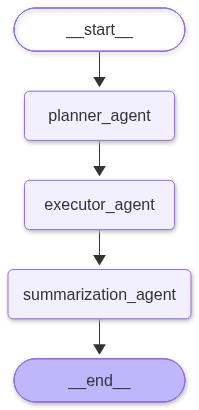

In [68]:
from IPython.display import Image, display

try:
    display(Image(workflow.get_graph().draw_mermaid_png()))
except Exception:
    print(workflow.get_graph().draw_mermaid())

## 8. Workflow Execution and Testing

In [69]:
user_query = "Write a Python script that calculates the factorial of a number and include unit tests for it."

print(f"User Query: {user_query}\n")

initial_state = State(user_query=user_query)
result = workflow.invoke(initial_state)

print(f"Goal: {result['goal']}\n")
print("=" * 60)
print("INDIVIDUAL TASK RESULTS IN STATE:")
print("=" * 60)

for task in result["tasks"]:
    print(f"Task {task.task_id}: {task.task}")
    print(f"  Status : {task.task_status}")
    if task.error:
        print(f"  Error  : {task.error}")
    elif task.result:
        print(f"  Result : {task.result[:120]}...")
    print()

print("=" * 60)
print("UNIFIED FINAL RESPONSE (FROM SUMMARIZATION AGENT):")
print("=" * 60)
print(result["final_response"])

User Query: Write a Python script that calculates the factorial of a number and include unit tests for it.

Goal: Create a Python script that calculates the factorial of a number and includes unit tests for the function.

============================================================

INDIVIDUAL TASK RESULTS IN STATE:

============================================================

Task 1: Write a Python function that calculates the factorial of a given non-negative integer.

... (8 outputs left out)

============================================================

UNIFIED FINAL RESPONSE (FROM SUMMARIZATION AGENT):

============================================================

```python
import unittest

def factorial(n: int) -> int:
    """
    Calculate the factorial of a non-negative integer n.

    Args:
        n (int): A non-negative integer whose factorial is to be computed.

    Returns:
        int: The factorial of n.

    Raises:
        ValueError: If n is negative.
        TypeError: If n is not an integer.
    """
    if not isinstance(n, int):
        raise TypeError("Input must be an integer.")
    if n < 0:
        raise ValueError("Input must be a non-negative integer.")
    result = 1
    for i in range(2, n + 1):
        result *= i
    return result


class TestFactorial(unittest.TestCase):
    def test_factorial_typical_cases(self):
        self.assertEqual(factorial(5), 120)
        self.assertEqual(factorial(3), 6)
        self.assertEqual(factorial(1), 1)
        self.assertEqual(factorial(4), 24)

    def test_factorial_edge_cases(self):
        self.assertEqual(factorial(0), 1)  # 0! is 1 by definition

    def test_factorial_invalid_input_type(self):
        with self.assertRaises(TypeError):
            factorial(3.5)
        with self.assertRaises(TypeError):
            factorial("5")
        with self.assertRaises(TypeError):
            factorial(None)

    def test_factorial_negative_input(self):
        with self.assertRaises(ValueError):
            factorial(-1)
        with self.assertRaises(ValueError):
            factorial(-10)


if __name__ == "__main__":
    unittest.main()
```